# Final Model — Test Prediction + OOD Detection

This notebook is the final evaluation version of the model and follows the same overall structure as `FinalModel.ipynb`.

The main difference is that, in addition to predicting the 8 known classes, **Energy and Mahalanobis thresholds** are applied to the test data to flag unknown images such as `neysan` as one of the following:

- `known`
- `needs_review`
- `unknown`

The notebook also provides detailed model analysis, including:

1. Loss and accuracy on known test images
2. Exactly misclassified images
3. Grad-CAM visualizations for wrong predictions
4. Images classified as `unknown`
5. Images classified as `needs_review`
6. `neysan` images missed by the OOD detector
7. Confusion matrix
8. Classification report

> **Important:** True loss and accuracy require ground-truth labels. If `neysan` is stored in a separate test folder, those images are excluded from the 8-class accuracy calculation and evaluated separately as OOD. If `neysan` images are mixed inside the 8 known-class folders without separate ground-truth labels, the notebook can flag suspicious images, but it cannot measure the true Neysan detection accuracy.

In [6]:
import torch
import torch.nn as nn
from torchvision import models, transforms, datasets
from torchvision.models import ResNet18_Weights
from torch.utils.data import DataLoader
from torchvision.datasets import ImageFolder
import torch.nn.functional as F

import sys
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import math
import re

from PIL import Image
from sklearn.covariance import LedoitWolf
from sklearn.metrics import classification_report, confusion_matrix, ConfusionMatrixDisplay

# Project root
PROJECT_DIR = Path.cwd().parent

if str(PROJECT_DIR) not in sys.path:
    sys.path.insert(0, str(PROJECT_DIR))

sys.path.append("../src")

from data import letterbox, create_train_val_datasets
from utils import get_classification_report, plot_confusion_matrix

DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")

IMAGENET_MEAN = [0.485, 0.456, 0.406]
IMAGENET_STD = [0.229, 0.224, 0.225]

MERGED_TRAIN_DIR = PROJECT_DIR / "dataset" / "merged_train"
UNSEEN_DIR = PROJECT_DIR / "dataset" / "neysan"
EVALUATE_STANDALONE_NEYSAN = True
# Select one test dataset at a time.
# Examples matching the project test protocol: test0, test1_2, test2, test3, test4.
TEST_DATASET_NAME = "test"
TEST_DIR = PROJECT_DIR / "dataset" / TEST_DATASET_NAME

# Optional ground-truth manifest for mixed/relabeled test sets (test2/test3/test4).
# Required columns: image_path, is_true_nissan. Optional: true_class.
GROUND_TRUTH_CSV = None

CHECKPOINT_PATH = (
    PROJECT_DIR
    / "checkpoints"
    / "resnet18_full_finetuning_non_letterbox_best.pt"
)

# Final OOD settings
QUANTILE = 0.95
CONFIDENCE_THRESHOLD = 0.70

# Possible names for an unseen Nissan/Neysan folder.
NISSAN_NAMES = {
    "neysan"
}

# Output directories
RESULTS_DIR = PROJECT_DIR / "results" / "FinalPredict_OOD"
CSV_DIR = RESULTS_DIR / "csv"
GRADCAM_DIR = RESULTS_DIR / "gradcam"
IMAGE_DIR = RESULTS_DIR / "images"

for output_dir in [CSV_DIR, GRADCAM_DIR, IMAGE_DIR]:
    output_dir.mkdir(parents=True, exist_ok=True)

print("Device:", DEVICE)
print("Test directory:", TEST_DIR)
print("Standalone Neysan directory:", UNSEEN_DIR)
print("Checkpoint:", CHECKPOINT_PATH)
print("Results directory:", RESULTS_DIR)


Device: cpu
Test directory: d:\AI Bootcamp_M Sharif\traffic_vehicle_project\dataset\test
Standalone Neysan directory: d:\AI Bootcamp_M Sharif\traffic_vehicle_project\dataset\neysan
Checkpoint: d:\AI Bootcamp_M Sharif\traffic_vehicle_project\checkpoints\resnet18_full_finetuning_non_letterbox_best.pt
Results directory: d:\AI Bootcamp_M Sharif\traffic_vehicle_project\results\FinalPredict_OOD


## Test Dataset Protocol

Select the dataset in `TEST_DATASET_NAME` in the configuration cell. The notebook supports the 8-class model and the OOD scenarios without changing the model architecture.

| Dataset | Structure | What can be measured |
|---|---|---|
| test0 | 8 known classes | True 8-class loss/accuracy + errors + Grad-CAM |
| test1 | 9 classes | Not required for this 8-class model |
| test1_2 | 9 classes including Neysan | 8-class metrics + explicit Neysan OOD evaluation |
| test2 | 8 folders, Neysan mixed into Vanet | OOD suspicion; exact Neysan metrics need ground truth |
| test3 | 8 folders, Neysan mixed across classes | OOD suspicion; exact Neysan metrics need ground truth |
| test4 | 8 folders, Neysan mixed with Vanet + label issues | OOD suspicion; exact semantic accuracy needs ground truth |


## 1. Test Preprocessing

The same preprocessing used in `FinalModel.ipynb` is applied:

- Letterbox → 224×224
- Convert to Tensor
- ImageNet normalization

In [7]:
test_transform = transforms.Compose([
    transforms.Lambda(
        lambda img: letterbox(
            img,
            target_size=(224, 224)
        )
    ),
    transforms.ToTensor(),
    transforms.Normalize(
        mean=IMAGENET_MEAN,
        std=IMAGENET_STD
    ),
])


## 2. Load Known Train/Validation Data

OOD thresholds must not be determined using `neysan` images.

Therefore:

- The feature distribution is built from the known training data.
- Energy and Mahalanobis scores are computed on known validation data.
- The 95th percentile of the validation scores is used as the threshold.
- The fixed thresholds are then applied to the test set.

In [8]:
train_dataset, val_dataset, train_indices, val_indices, class_to_idx = (
    create_train_val_datasets(
        data_dir=MERGED_TRAIN_DIR,
        train_transform=test_transform,
        val_transform=test_transform,
        test_size=0.2,
        seed=7,
    )
)

full_train_dataset = datasets.ImageFolder(MERGED_TRAIN_DIR)
class_names = full_train_dataset.classes

print("Train:", len(train_dataset))
print("Val:", len(val_dataset))
print("Known classes:", class_names)


Train: 2713
Val: 679
Known classes: ['ambulance', 'autobus', 'kamyun', 'kamyunet', 'minibus', 'savari', 'taxi', 'vanet']


## 3. Load Final ResNet18 Model

In [9]:
checkpoint = torch.load(
    CHECKPOINT_PATH,
    map_location=DEVICE
)

model = models.resnet18(
    weights=ResNet18_Weights.DEFAULT
)

model.fc = nn.Linear(
    model.fc.in_features,
    8
)

model.load_state_dict(
    checkpoint["model_state_dict"]
)

model = model.to(DEVICE)
model.eval()

print("Checkpoint:", CHECKPOINT_PATH)
print("Best Epoch:", checkpoint.get("epoch"))
print("Best Val Accuracy:", checkpoint.get("val_accuracy"))


Checkpoint: d:\AI Bootcamp_M Sharif\traffic_vehicle_project\checkpoints\resnet18_full_finetuning_non_letterbox_best.pt
Best Epoch: 122
Best Val Accuracy: 0.9837997054491899


## 4. Test Dataset

This notebook is designed to support the project test protocol:

- **test0:** 8 known classes only. Standard 8-class evaluation.
- **test1:** 9 classes including Neysan. This dataset is intentionally not required for this 8-class model.
- **test1_2:** 9 classes including Neysan, with additional class-label issues. The notebook can load it while keeping the model output layer at 8 classes.
- **test2:** 8 folder classes, with some Neysan images mixed into the `vanet` folder. Without external ground truth, OOD can only flag suspicious images.
- **test3:** 8 folder classes, with Neysan images mixed into other classes. Exact Neysan detection accuracy requires ground-truth labels.
- **test4:** 8 folder classes, with Neysan mixed with `vanet` and `kamyun`/`kamyunet` labeling issues. Exact semantic accuracy requires reliable ground truth.

For test2/test3/test4, set `GROUND_TRUTH_CSV` if you have an annotation file containing the true Neysan status.


In [10]:
test_dataset = ImageFolder(TEST_DIR, transform=test_transform)

test_loader = DataLoader(
    test_dataset,
    batch_size=32,
    shuffle=False,
    num_workers=0,
)

print("Selected test dataset:", TEST_DATASET_NAME)
print("Test directory:", TEST_DIR)
print("Test classes:", test_dataset.classes)
print("Total test images:", len(test_dataset))

# The model always predicts the original 8 known classes.
# Do not use test ImageFolder indices as model indices when a ninth folder exists.
model_class_to_idx = {name: i for i, name in enumerate(class_names)}
nissan_names_lower = {x.lower() for x in NISSAN_NAMES}

nissan_indices = [
    i for i, name in enumerate(test_dataset.classes)
    if name.lower() in nissan_names_lower
]

known_test_class_names = [
    name for name in test_dataset.classes
    if name in model_class_to_idx
]

unknown_test_class_names = [
    name for name in test_dataset.classes
    if name not in model_class_to_idx and name.lower() not in nissan_names_lower
]

print("Known test classes found:", known_test_class_names)
print("Explicit Neysan/Nissan classes:", [test_dataset.classes[i] for i in nissan_indices])
if unknown_test_class_names:
    print("Warning — test folders not present in the 8-class model:", unknown_test_class_names)

ground_truth_df = None
if GROUND_TRUTH_CSV is not None:
    ground_truth_df = pd.read_csv(GROUND_TRUTH_CSV)
    required = {"image_path", "is_true_nissan"}
    missing = required - set(ground_truth_df.columns)
    if missing:
        raise ValueError(f"GROUND_TRUTH_CSV is missing required columns: {sorted(missing)}")
    ground_truth_df["image_path"] = ground_truth_df["image_path"].astype(str)
    print("Loaded external ground-truth manifest:", GROUND_TRUTH_CSV)


Selected test dataset: test
Test directory: d:\AI Bootcamp_M Sharif\traffic_vehicle_project\dataset\test
Test classes: ['ambulance', 'autobus', 'kamyun', 'kamyunet', 'minibus', 'savari', 'taxi', 'vanet']
Total test images: 400
Known test classes found: ['ambulance', 'autobus', 'kamyun', 'kamyunet', 'minibus', 'savari', 'taxi', 'vanet']
Explicit Neysan/Nissan classes: []


## 5. Extract 512-D ResNet18 Features

In [11]:
def extract_features(model, x):
    x = model.conv1(x)
    x = model.bn1(x)
    x = model.relu(x)
    x = model.maxpool(x)

    x = model.layer1(x)
    x = model.layer2(x)
    x = model.layer3(x)
    x = model.layer4(x)

    x = model.avgpool(x)
    x = torch.flatten(x, 1)

    return x


## 6. Build Mahalanobis Feature Bank From Known Training Data

In [12]:
def collect_features(model, dataloader, device):
    model.eval()

    all_features = []
    all_labels = []

    with torch.no_grad():
        for images, labels in dataloader:
            images = images.to(device)

            features = extract_features(
                model,
                images
            )

            all_features.append(features.cpu())
            all_labels.append(labels.cpu())

    return (
        torch.cat(all_features),
        torch.cat(all_labels)
    )


train_loader_features = DataLoader(
    train_dataset,
    batch_size=64,
    shuffle=False,
    num_workers=0
)

train_features, train_labels = collect_features(
    model,
    train_loader_features,
    DEVICE
)

print("Feature shape:", train_features.shape)
print("Label shape:", train_labels.shape)


Feature shape: torch.Size([2713, 512])
Label shape: torch.Size([2713])


In [13]:
NUM_CLASSES = 8

class_means = []

for class_idx in range(NUM_CLASSES):

    class_features = train_features[
        train_labels == class_idx
    ]

    mean = class_features.mean(dim=0)
    class_means.append(mean)

class_means = torch.stack(class_means)

print("Class means:", class_means.shape)


Class means: torch.Size([8, 512])


## 7. Ledoit-Wolf Covariance

In [14]:
lw = LedoitWolf()

lw.fit(
    train_features.numpy()
)

covariance = lw.covariance_

precision = np.linalg.inv(
    covariance
)

precision = torch.tensor(
    precision,
    dtype=torch.float32
)

print("Covariance:", covariance.shape)
print("Precision:", precision.shape)


Covariance: (512, 512)
Precision: torch.Size([512, 512])


## 8. Energy and Mahalanobis Functions

In [15]:
def energy_score(logits, temperature=1.0):

    return -temperature * torch.logsumexp(
        logits / temperature,
        dim=1
    )


def mahalanobis_score(
    features,
    class_means,
    precision
):

    scores = []

    for mean in class_means:

        diff = features - mean

        distance = torch.sqrt(
            torch.sum(
                (diff @ precision) * diff,
                dim=1
            ).clamp_min(0)
        )

        scores.append(distance)

    scores = torch.stack(
        scores,
        dim=1
    )

    min_distance, predicted_class = scores.min(
        dim=1
    )

    return min_distance, predicted_class


## 9. Calculate OOD Thresholds

The thresholds are computed **only from known validation data**.

```python
threshold = quantile(validation_scores, 0.95)
```

Therefore, `neysan` images have no role in threshold selection.

In [16]:
val_loader_features = DataLoader(
    val_dataset,
    batch_size=64,
    shuffle=False,
    num_workers=0
)

val_energy = []
val_maha = []

with torch.no_grad():

    for images, labels in val_loader_features:

        images = images.to(DEVICE)

        logits = model(images)

        features = extract_features(
            model,
            images
        )

        energy = energy_score(
            logits
        )

        maha, _ = mahalanobis_score(
            features.cpu(),
            class_means.cpu(),
            precision.cpu()
        )

        val_energy.append(
            energy.cpu()
        )

        val_maha.append(
            maha.cpu()
        )

val_energy = torch.cat(val_energy)
val_maha = torch.cat(val_maha)

energy_threshold = torch.quantile(
    val_energy,
    QUANTILE
).item()

maha_threshold = torch.quantile(
    val_maha,
    QUANTILE
).item()

print("Energy threshold:", energy_threshold)
print("Mahalanobis threshold:", maha_threshold)
print("Quantile:", QUANTILE)


Energy threshold: -5.905742168426514
Mahalanobis threshold: 20.15118980407715
Quantile: 0.95


## 10. Final Prediction Rule

For every image, four factors are considered:

- Predicted class
- Confidence
- Energy OOD score
- Mahalanobis OOD score

The final decision rule is:

```text
Energy OOD + Mahalanobis OOD
              ↓
           UNKNOWN

Only one detector flags OOD
              ↓
        NEEDS REVIEW

Neither detector flags OOD, but confidence < 0.70
              ↓
        NEEDS REVIEW

Neither detector flags OOD and confidence >= 0.70
              ↓
            KNOWN
```

For true `neysan` images, if neither detector flags OOD, the result is labeled `known_failure` during evaluation. This means the image is actually OOD, but the detector failed to reject it and the classifier assigned it to one of the 8 known classes.

> **Standalone Neysan evaluation:** the folder `dataset/neysan` is treated as an independent OOD benchmark. It is not added to the 8-class `ImageFolder` used for the known test metrics.


In [17]:
def classify_status(
    energy_ood,
    maha_ood,
    confidence,
    confidence_threshold=0.70
):

    if energy_ood and maha_ood:
        return "unknown"

    elif energy_ood or maha_ood:
        return "needs_review"

    elif confidence < confidence_threshold:
        return "needs_review"

    else:
        return "known"


## 10.1 Standalone Neysan OOD Evaluation

The model remains an 8-class classifier. The standalone `dataset/neysan` folder is **not** added to the model's class mapping. Instead, its images are passed through the trained model and evaluated using the already-fixed Energy and Mahalanobis thresholds.

This section is important because keeping Neysan outside `dataset/test` means the 8-class test loader does not see it. We therefore evaluate `dataset/neysan` separately as an OOD benchmark.


In [18]:
class FlatImageDataset(torch.utils.data.Dataset):
    """Dataset for a flat folder such as dataset/neysan/*.jpg."""

    def __init__(self, root, transform=None):
        self.root = Path(root)
        self.transform = transform
        extensions = {".jpg", ".jpeg", ".png", ".bmp", ".webp"}
        self.paths = sorted(
            p for p in self.root.iterdir()
            if p.is_file() and p.suffix.lower() in extensions
        )
        self.classes = ["neysan"]
        self.class_to_idx = {"neysan": 0}
        self.samples = [(str(p), 0) for p in self.paths]

    def __len__(self):
        return len(self.samples)

    def __getitem__(self, index):
        path, label = self.samples[index]
        image = Image.open(path).convert("RGB")
        if self.transform is not None:
            image = self.transform(image)
        return image, label


if EVALUATE_STANDALONE_NEYSAN and UNSEEN_DIR.exists():
    # Support both structures:
    #   dataset/neysan/neysan/*.jpg   (ImageFolder style)
    #   dataset/neysan/*.jpg          (flat folder)
    subdirs = [p for p in UNSEEN_DIR.iterdir() if p.is_dir()]
    if subdirs:
        standalone_nissan_dataset = ImageFolder(
            UNSEEN_DIR,
            transform=test_transform,
        )
    else:
        standalone_nissan_dataset = FlatImageDataset(
            UNSEEN_DIR,
            transform=test_transform,
        )

    standalone_nissan_loader = DataLoader(
        standalone_nissan_dataset,
        batch_size=32,
        shuffle=False,
        num_workers=0,
    )

    standalone_rows = []
    model.eval()
    standalone_sample_counter = 0

    with torch.no_grad():
        for images, labels in standalone_nissan_loader:
            images = images.to(DEVICE)

            logits = model(images)
            probabilities = torch.softmax(logits, dim=1)
            confidence, predictions = probabilities.max(dim=1)
            energy = energy_score(logits)
            features = extract_features(model, images)
            maha_distance, _ = mahalanobis_score(
                features,
                class_means.to(DEVICE),
                precision.to(DEVICE),
            )

            energy_ood = energy > energy_threshold
            maha_ood = maha_distance > maha_threshold

            for i in range(len(labels)):
                image_path = standalone_nissan_dataset.samples[
                    standalone_sample_counter
                ][0]
                pred_idx = predictions[i].item()
                conf_value = confidence[i].item()
                e_ood = bool(energy_ood[i].item())
                m_ood = bool(maha_ood[i].item())
                status = classify_status(
                    e_ood,
                    m_ood,
                    conf_value,
                    CONFIDENCE_THRESHOLD,
                )

                if status == "known":
                    status = "known_failure"

                standalone_rows.append({
                    "image_path": image_path,
                    "true_class": "neysan",
                    "predicted_class": class_names[pred_idx],
                    "confidence": conf_value,
                    "loss": np.nan,
                    "energy": energy[i].item(),
                    "mahalanobis": maha_distance[i].item(),
                    "energy_ood": e_ood,
                    "mahalanobis_ood": m_ood,
                    "status": status,
                    "is_true_nissan": True,
                    "has_explicit_nissan_label": True,
                    "has_external_ground_truth": True,
                    "source": "standalone_dataset_neysan",
                })
                standalone_sample_counter += 1

    standalone_nissan_results = pd.DataFrame(standalone_rows)
    standalone_csv = CSV_DIR / "standalone_neysan_results.csv"
    standalone_nissan_results.to_csv(standalone_csv, index=False)

    print("Standalone Neysan images:", len(standalone_nissan_results))
    print("Saved:", standalone_csv)

    counts = standalone_nissan_results["status"].value_counts()
    for status in ["unknown", "needs_review", "known_failure"]:
        count = int(counts.get(status, 0))
        rate = count / len(standalone_nissan_results) * 100 if len(standalone_nissan_results) else 0
        print(f"{status:15s}: {count:4d} ({rate:.2f}%)")
else:
    standalone_nissan_results = pd.DataFrame()
    if EVALUATE_STANDALONE_NEYSAN:
        print(f"Standalone Neysan directory not found: {UNSEEN_DIR}")


Standalone Neysan images: 586
Saved: d:\AI Bootcamp_M Sharif\traffic_vehicle_project\results\FinalPredict_OOD\csv\standalone_neysan_results.csv
unknown        :   15 (2.56%)
needs_review   :  170 (29.01%)
known_failure  :  401 (68.43%)


## 11. Predict All Test Images

In addition to the prediction, the following information is stored for every test image:

- image path
- true class
- predicted class
- confidence
- loss
- Energy score
- Mahalanobis score
- OOD flags
- final status

These results are stored in a DataFrame and reused for visualization and analysis.

In [19]:
results = []
criterion = nn.CrossEntropyLoss(reduction="none")
model.eval()
sample_counter = 0

with torch.no_grad():
    for images, labels in test_loader:
        images = images.to(DEVICE)
        labels = labels.to(DEVICE)

        logits = model(images)
        probabilities = torch.softmax(logits, dim=1)
        confidence, predictions = probabilities.max(dim=1)
        energy = energy_score(logits)
        features = extract_features(model, images)
        maha_distance, _ = mahalanobis_score(
            features, class_means.to(DEVICE), precision.to(DEVICE)
        )

        energy_ood = energy > energy_threshold
        maha_ood = maha_distance > maha_threshold

        for i in range(len(labels)):
            test_idx = labels[i].item()
            pred_idx = predictions[i].item()
            true_name = test_dataset.classes[test_idx]
            image_path = test_dataset.samples[sample_counter][0]

            explicit_nissan = test_idx in nissan_indices
            is_true_nissan = explicit_nissan
            true_model_idx = model_class_to_idx.get(true_name, None)

            # Optional external manifest overrides folder-based ground truth.
            if ground_truth_df is not None:
                matched = ground_truth_df[ground_truth_df["image_path"] == str(image_path)]
                if len(matched) == 1:
                    row = matched.iloc[0]
                    is_true_nissan = bool(row["is_true_nissan"])
                    if "true_class" in ground_truth_df.columns and pd.notna(row.get("true_class")):
                        true_name = str(row["true_class"])
                    true_model_idx = model_class_to_idx.get(true_name, None)

            # Only known 8-class samples receive a classification loss.
            if true_model_idx is not None and not is_true_nissan:
                loss_value = criterion(
                    logits[i:i+1],
                    torch.tensor([true_model_idx], device=DEVICE),
                )[0].item()
            else:
                loss_value = np.nan

            conf_value = confidence[i].item()
            e_ood = bool(energy_ood[i].item())
            m_ood = bool(maha_ood[i].item())
            status = classify_status(e_ood, m_ood, conf_value, CONFIDENCE_THRESHOLD)

            if is_true_nissan and status == "known":
                status = "known_failure"

            results.append({
                "image_path": image_path,
                "true_class": true_name,
                "predicted_class": class_names[pred_idx],
                "confidence": conf_value,
                "loss": loss_value,
                "energy": energy[i].item(),
                "mahalanobis": maha_distance[i].item(),
                "energy_ood": e_ood,
                "mahalanobis_ood": m_ood,
                "status": status,
                "is_true_nissan": is_true_nissan,
                "has_explicit_nissan_label": explicit_nissan,
                "has_external_ground_truth": ground_truth_df is not None,
            })
            sample_counter += 1

results_df = pd.DataFrame(results)
print("Total predictions:", len(results_df))
display(results_df.head())


Total predictions: 400


,image_path,true_class,predicted_class,confidence,loss,energy,mahalanobis,energy_ood,mahalanobis_ood,status,is_true_nissan,has_explicit_nissan_label,has_external_ground_truth
0,d:\AI Bootcamp_M Sharif\traffic_vehicle_projec...,ambulance,ambulance,0.999968,0.000032,-10.826432,23.703510,False,True,needs_review,False,False,False
1,d:\AI Bootcamp_M Sharif\traffic_vehicle_projec...,ambulance,ambulance,0.999997,0.000003,-11.915893,14.523033,False,False,known,False,False,False
2,d:\AI Bootcamp_M Sharif\traffic_vehicle_projec...,ambulance,ambulance,0.999997,0.000003,-11.952332,12.634245,False,False,known,False,False,False
3,d:\AI Bootcamp_M Sharif\traffic_vehicle_projec...,ambulance,ambulance,0.999882,0.000118,-9.277369,14.089764,False,False,known,False,False,False
4,d:\AI Bootcamp_M Sharif\traffic_vehicle_projec...,ambulance,ambulance,0.999996,0.000004,-13.954575,19.963249,False,False,known,False,False,False


## 12. Save Per-Image Prediction Results

The complete prediction table is saved as a CSV file so every test image can be inspected later without rerunning inference.


In [20]:
all_results_csv = CSV_DIR / "FinalPredict_OOD_results.csv"
results_df.to_csv(all_results_csv, index=False)

print(f"Saved: {all_results_csv}")
print(f"Rows: {len(results_df)}")


Saved: d:\AI Bootcamp_M Sharif\traffic_vehicle_project\results\FinalPredict_OOD\csv\FinalPredict_OOD_results.csv
Rows: 400


## 12. Loss and Accuracy

Standard 8-class loss and accuracy are computed only when reliable known-class ground truth is available.

- Explicit `neysan`/`nissan` samples are excluded from 8-class metrics.
- For test2/test3/test4, folder labels are the available ground truth unless `GROUND_TRUTH_CSV` is provided. Therefore, if Neysan is hidden inside a known folder, the metric is **folder-label accuracy**, not true semantic accuracy.
- An external manifest can provide exact `is_true_nissan` labels and corrected `true_class` values.


In [21]:
known_mask = (
    ~results_df["is_true_nissan"]
    & results_df["true_class"].isin(class_names)
    & results_df["loss"].notna()
)
known_results = results_df[known_mask].copy()

known_accuracy = (
    (known_results["true_class"] == known_results["predicted_class"]).mean()
    if len(known_results) else np.nan
)
known_loss = known_results["loss"].mean() if len(known_results) else np.nan

print("=" * 60)
print("KNOWN TEST PERFORMANCE")
print("=" * 60)
print(f"Known Test Loss     : {known_loss:.6f}" if not np.isnan(known_loss) else "Known Test Loss     : N/A")
print(f"Known Test Accuracy : {known_accuracy * 100:.2f}%" if not np.isnan(known_accuracy) else "Known Test Accuracy : N/A")
print(f"Known Test Samples  : {len(known_results)}")

if not results_df["has_explicit_nissan_label"].any() and GROUND_TRUTH_CSV is None:
    print("\nNOTE: No explicit Neysan labels or external ground truth were provided.")
    print("OOD flags are available, but true Neysan detection accuracy cannot be measured.")


KNOWN TEST PERFORMANCE
Known Test Loss     : 0.064108
Known Test Accuracy : 98.50%
Known Test Samples  : 400

NOTE: No explicit Neysan labels or external ground truth were provided.
OOD flags are available, but true Neysan detection accuracy cannot be measured.


## 13. Exactly Wrong Predictions

This table shows exactly which known test images were misclassified by the model.

These errors are separate from OOD cases because their ground-truth class belongs to one of the 8 known classes.

In [22]:
wrong_predictions = results_df[
    known_mask
    & (
        results_df["true_class"]
        != results_df["predicted_class"]
    )
].copy()

print(
    "Number of wrong known predictions:",
    len(wrong_predictions)
)

display(
    wrong_predictions[
        [
            "image_path",
            "true_class",
            "predicted_class",
            "confidence",
            "energy",
            "mahalanobis",
            "status",
        ]
    ]
)

wrong_predictions.to_csv(CSV_DIR / "wrong_predictions.csv", index=False)
print(f"Saved: {CSV_DIR / 'wrong_predictions.csv'}")


Number of wrong known predictions: 6


,image_path,true_class,predicted_class,confidence,energy,mahalanobis,status
19,d:\AI Bootcamp_M Sharif\traffic_vehicle_projec...,ambulance,vanet,0.997214,-8.893118,17.527828,known
108,d:\AI Bootcamp_M Sharif\traffic_vehicle_projec...,kamyun,kamyunet,0.995418,-6.498110,15.215924,known
112,d:\AI Bootcamp_M Sharif\traffic_vehicle_projec...,kamyun,kamyunet,0.965774,-6.992775,19.469696,known
113,d:\AI Bootcamp_M Sharif\traffic_vehicle_projec...,kamyun,minibus,0.584500,-3.686175,15.379316,needs_review
122,d:\AI Bootcamp_M Sharif\traffic_vehicle_projec...,kamyun,kamyunet,0.973528,-5.219103,14.077501,needs_review
134,d:\AI Bootcamp_M Sharif\traffic_vehicle_projec...,kamyun,kamyunet,0.577381,-4.658116,22.384155,unknown


Saved: d:\AI Bootcamp_M Sharif\traffic_vehicle_project\results\FinalPredict_OOD\csv\wrong_predictions.csv


## 14. Plot Wrong Predictions With Grad-CAM

In [23]:
class GradCAM:

    def __init__(
        self,
        model,
        target_layer
    ):

        self.model = model
        self.activations = None
        self.gradients = None

        target_layer.register_forward_hook(
            self._save_activation
        )

        target_layer.register_full_backward_hook(
            self._save_gradient
        )

    def _save_activation(
        self,
        module,
        input,
        output
    ):

        self.activations = output.detach()

    def _save_gradient(
        self,
        module,
        grad_input,
        grad_output
    ):

        self.gradients = grad_output[0].detach()

    def generate(
        self,
        input_tensor,
        class_idx=None
    ):

        self.model.zero_grad()

        output = self.model(
            input_tensor
        )

        if class_idx is None:
            class_idx = output.argmax(
                dim=1
            ).item()

        output[:, class_idx].backward()

        pooled_grad = self.gradients.mean(
            dim=[0, 2, 3]
        )

        activations = self.activations.squeeze(
            0
        ).clone()

        for i in range(
            activations.shape[0]
        ):

            activations[i] *= pooled_grad[i]

        heatmap = activations.mean(
            dim=0
        ).cpu().numpy()

        heatmap = np.maximum(
            heatmap,
            0
        )

        heatmap = heatmap / (
            heatmap.max() + 1e-8
        )

        return heatmap, class_idx


def overlay_heatmap(
    image_np,
    heatmap,
    alpha=0.35
):

    heatmap_img = Image.fromarray(
        np.uint8(heatmap * 255)
    ).resize(
        (
            image_np.shape[1],
            image_np.shape[0]
        ),
        resample=Image.BILINEAR
    )

    heatmap_colored = plt.cm.jet(
        np.array(heatmap_img) / 255.0
    )[..., :3]

    return (
        (1 - alpha) * image_np
        + alpha * heatmap_colored
    )


gradcam = GradCAM(
    model,
    model.layer4
)


In [24]:
def _safe_filename(text):
    text = str(text)
    return re.sub(r"[^A-Za-z0-9_.-]+", "_", text).strip("_") or "image"


def save_original_image(image_path, destination_dir, row_index):
    destination_dir = Path(destination_dir)
    destination_dir.mkdir(parents=True, exist_ok=True)
    src = Path(image_path)
    name = f"{row_index:05d}_{_safe_filename(src.stem)}{src.suffix.lower()}"
    Image.open(src).convert("RGB").save(destination_dir / name)
    return destination_dir / name


def plot_gradcam_dataframe(
    dataframe,
    title,
    max_images=12,
    cols=3,
    save_dir=None,
    save_all_individual=False,
    save_originals=False,
):
    df = dataframe.copy()

    if len(df) == 0:
        print("No images to plot.")
        return

    if save_dir is not None:
        save_dir = Path(save_dir)
        save_dir.mkdir(parents=True, exist_ok=True)

    display_df = df.head(max_images)
    rows = math.ceil(len(display_df) / cols)

    def make_overlay(item):
        img = Image.open(item["image_path"]).convert("RGB")
        input_tensor = test_transform(img).unsqueeze(0).to(DEVICE)
        heatmap, _ = gradcam.generate(
            input_tensor,
            class_idx=class_names.index(item["predicted_class"])
        )
        image_np = np.array(img.resize((224, 224))) / 255.0
        overlay = overlay_heatmap(image_np, heatmap, alpha=0.35)
        return overlay

    rows_to_save = df if save_all_individual else display_df
    for row_number, (_, item) in enumerate(rows_to_save.iterrows()):
        overlay = make_overlay(item)
        if save_dir is not None:
            stem = _safe_filename(Path(item["image_path"]).stem)
            base = f"{row_number:05d}_{stem}"
            plt.imsave(save_dir / f"{base}_gradcam.png", np.clip(overlay, 0, 1))
            if save_originals:
                save_original_image(item["image_path"], save_dir / "original", row_number)

    fig, axes = plt.subplots(rows, cols, figsize=(16, 4 * rows))
    axes = np.array(axes).reshape(-1)

    for ax, (_, item) in zip(axes, display_df.iterrows()):
        overlay = make_overlay(item)
        ax.imshow(overlay)
        ax.axis("off")
        ax.set_title(
            f'True: {item["true_class"]}\n'
            f'Pred: {item["predicted_class"]}\n'
            f'Conf: {item["confidence"]:.2%}\n'
            f'Status: {item["status"]}'
        )

    for ax in axes[len(display_df):]:
        ax.axis("off")

    fig.suptitle(title, fontsize=16)
    plt.tight_layout()

    if save_dir is not None:
        figure_name = _safe_filename(title.lower()) + "_grid.png"
        fig.savefig(save_dir / figure_name, dpi=200, bbox_inches="tight")
        print(f"Saved Grad-CAM grid: {save_dir / figure_name}")

    plt.show()
    plt.close(fig)


Saved Grad-CAM grid: d:\AI Bootcamp_M Sharif\traffic_vehicle_project\results\FinalPredict_OOD\gradcam\wrong_predictions\wrong_known_predictions_grad-cam_grid.png


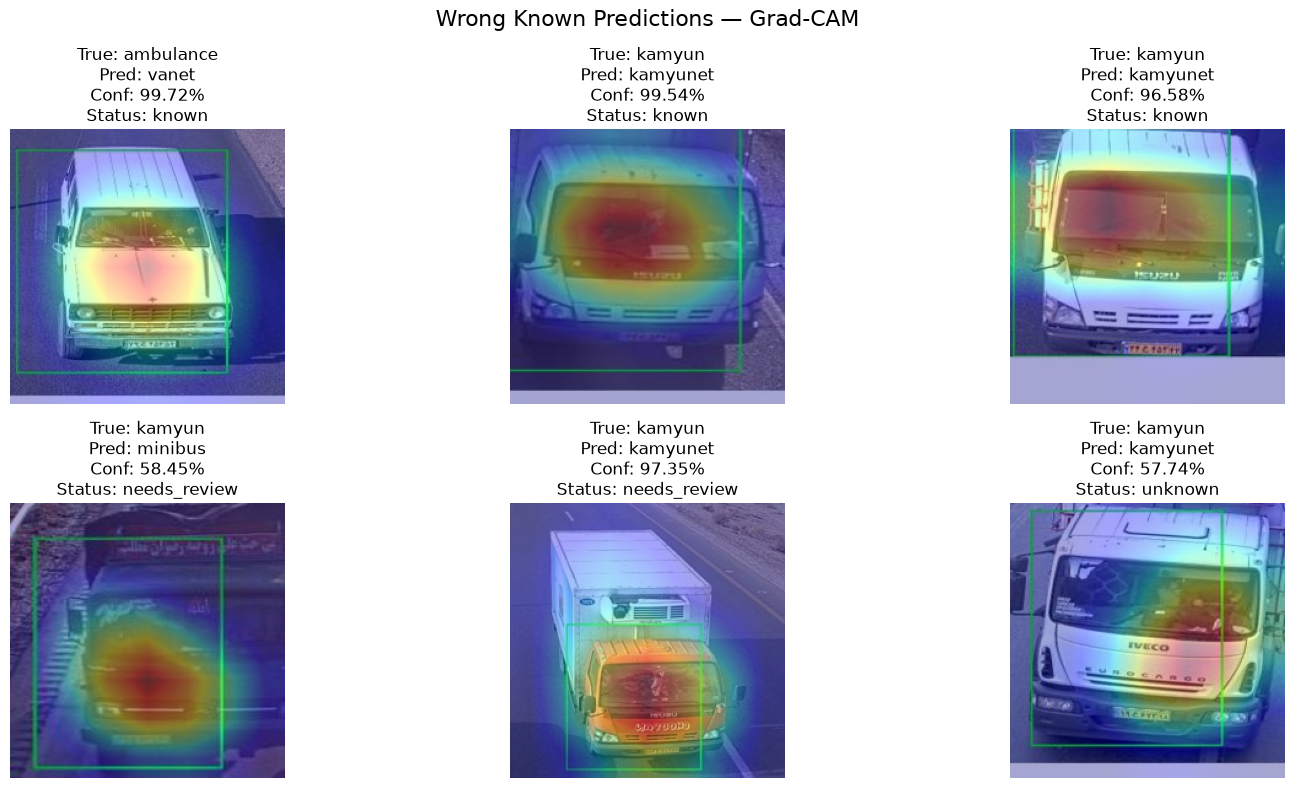

In [25]:
plot_gradcam_dataframe(
    wrong_predictions,
    "Wrong Known Predictions — Grad-CAM",
    max_images=12,
    save_dir=GRADCAM_DIR / "wrong_predictions",
    save_all_individual=True,
    save_originals=True,
)


## 15. Unknown Images

This section displays images for which **both** Energy and Mahalanobis detectors identify the sample as OOD.

This is the strongest `unknown` decision.

In [26]:
unknown_results = results_df[
    results_df["status"] == "unknown"
].copy()

print(
    "Unknown images:",
    len(unknown_results)
)

display(
    unknown_results[
        [
            "image_path",
            "true_class",
            "predicted_class",
            "confidence",
            "energy",
            "mahalanobis",
            "energy_ood",
            "mahalanobis_ood",
        ]
    ]
)

unknown_results.to_csv(CSV_DIR / "unknown_predictions.csv", index=False)
print(f"Saved: {CSV_DIR / 'unknown_predictions.csv'}")


Unknown images: 3


,image_path,true_class,predicted_class,confidence,energy,mahalanobis,energy_ood,mahalanobis_ood
59,d:\AI Bootcamp_M Sharif\traffic_vehicle_projec...,autobus,autobus,0.687176,-5.601271,21.205212,True,True
134,d:\AI Bootcamp_M Sharif\traffic_vehicle_projec...,kamyun,kamyunet,0.577381,-4.658116,22.384155,True,True
190,d:\AI Bootcamp_M Sharif\traffic_vehicle_projec...,kamyunet,kamyunet,0.916618,-5.411498,20.696054,True,True


Saved: d:\AI Bootcamp_M Sharif\traffic_vehicle_project\results\FinalPredict_OOD\csv\unknown_predictions.csv


Saved Grad-CAM grid: d:\AI Bootcamp_M Sharif\traffic_vehicle_project\results\FinalPredict_OOD\gradcam\unknown\unknown_images_energy_mahalanobis_grid.png


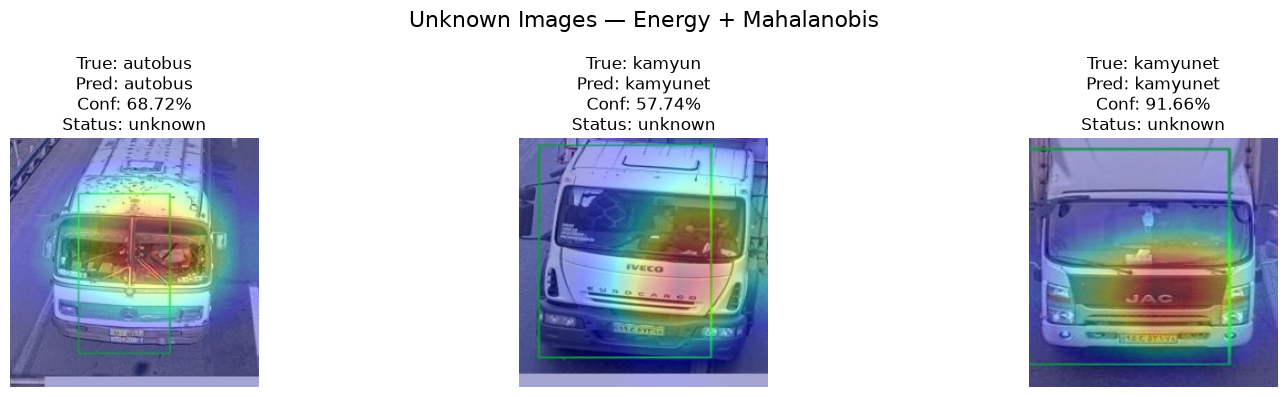

In [27]:
plot_gradcam_dataframe(
    unknown_results,
    "Unknown Images — Energy + Mahalanobis",
    max_images=12,
    save_dir=GRADCAM_DIR / "unknown",
    save_all_individual=True,
    save_originals=True,
)


## 16. Needs Review Images

This section displays images that either:

- are flagged as OOD by only one of the two detectors, or
- have model confidence below 70%.

These images should be considered for human review.

In [28]:
review_results = results_df[
    results_df["status"] == "needs_review"
].copy()

print(
    "Needs review images:",
    len(review_results)
)

display(
    review_results[
        [
            "image_path",
            "true_class",
            "predicted_class",
            "confidence",
            "energy",
            "mahalanobis",
            "energy_ood",
            "mahalanobis_ood",
        ]
    ]
)

review_results.to_csv(CSV_DIR / "needs_review_predictions.csv", index=False)
print(f"Saved: {CSV_DIR / 'needs_review_predictions.csv'}")


Needs review images: 47


,image_path,true_class,predicted_class,confidence,energy,mahalanobis,energy_ood,mahalanobis_ood
0,d:\AI Bootcamp_M Sharif\traffic_vehicle_projec...,ambulance,ambulance,0.999968,-10.826432,23.703510,False,True
6,d:\AI Bootcamp_M Sharif\traffic_vehicle_projec...,ambulance,ambulance,0.999994,-11.844053,20.859995,False,True
40,d:\AI Bootcamp_M Sharif\traffic_vehicle_projec...,ambulance,ambulance,0.971685,-4.583077,13.228782,True,False
41,d:\AI Bootcamp_M Sharif\traffic_vehicle_projec...,ambulance,ambulance,0.991635,-5.666773,12.163087,True,False
51,d:\AI Bootcamp_M Sharif\traffic_vehicle_projec...,autobus,autobus,0.990062,-5.239489,14.777165,True,False
52,d:\AI Bootcamp_M Sharif\traffic_vehicle_projec...,autobus,autobus,0.989950,-5.434518,15.876435,True,False
75,d:\AI Bootcamp_M Sharif\traffic_vehicle_projec...,autobus,autobus,0.999999,-13.089299,20.164667,False,True
98,d:\AI Bootcamp_M Sharif\traffic_vehicle_projec...,autobus,autobus,0.525016,-3.956197,18.714493,True,False
106,d:\AI Bootcamp_M Sharif\traffic_vehicle_projec...,kamyun,kamyun,0.952455,-4.478878,16.910896,True,False
109,d:\AI Bootcamp_M Sharif\traffic_vehicle_projec...,kamyun,kamyun,0.932072,-5.249305,15.857507,True,False


Saved: d:\AI Bootcamp_M Sharif\traffic_vehicle_project\results\FinalPredict_OOD\csv\needs_review_predictions.csv


Saved Grad-CAM grid: d:\AI Bootcamp_M Sharif\traffic_vehicle_project\results\FinalPredict_OOD\gradcam\needs_review\needs_review_images_grad-cam_grid.png


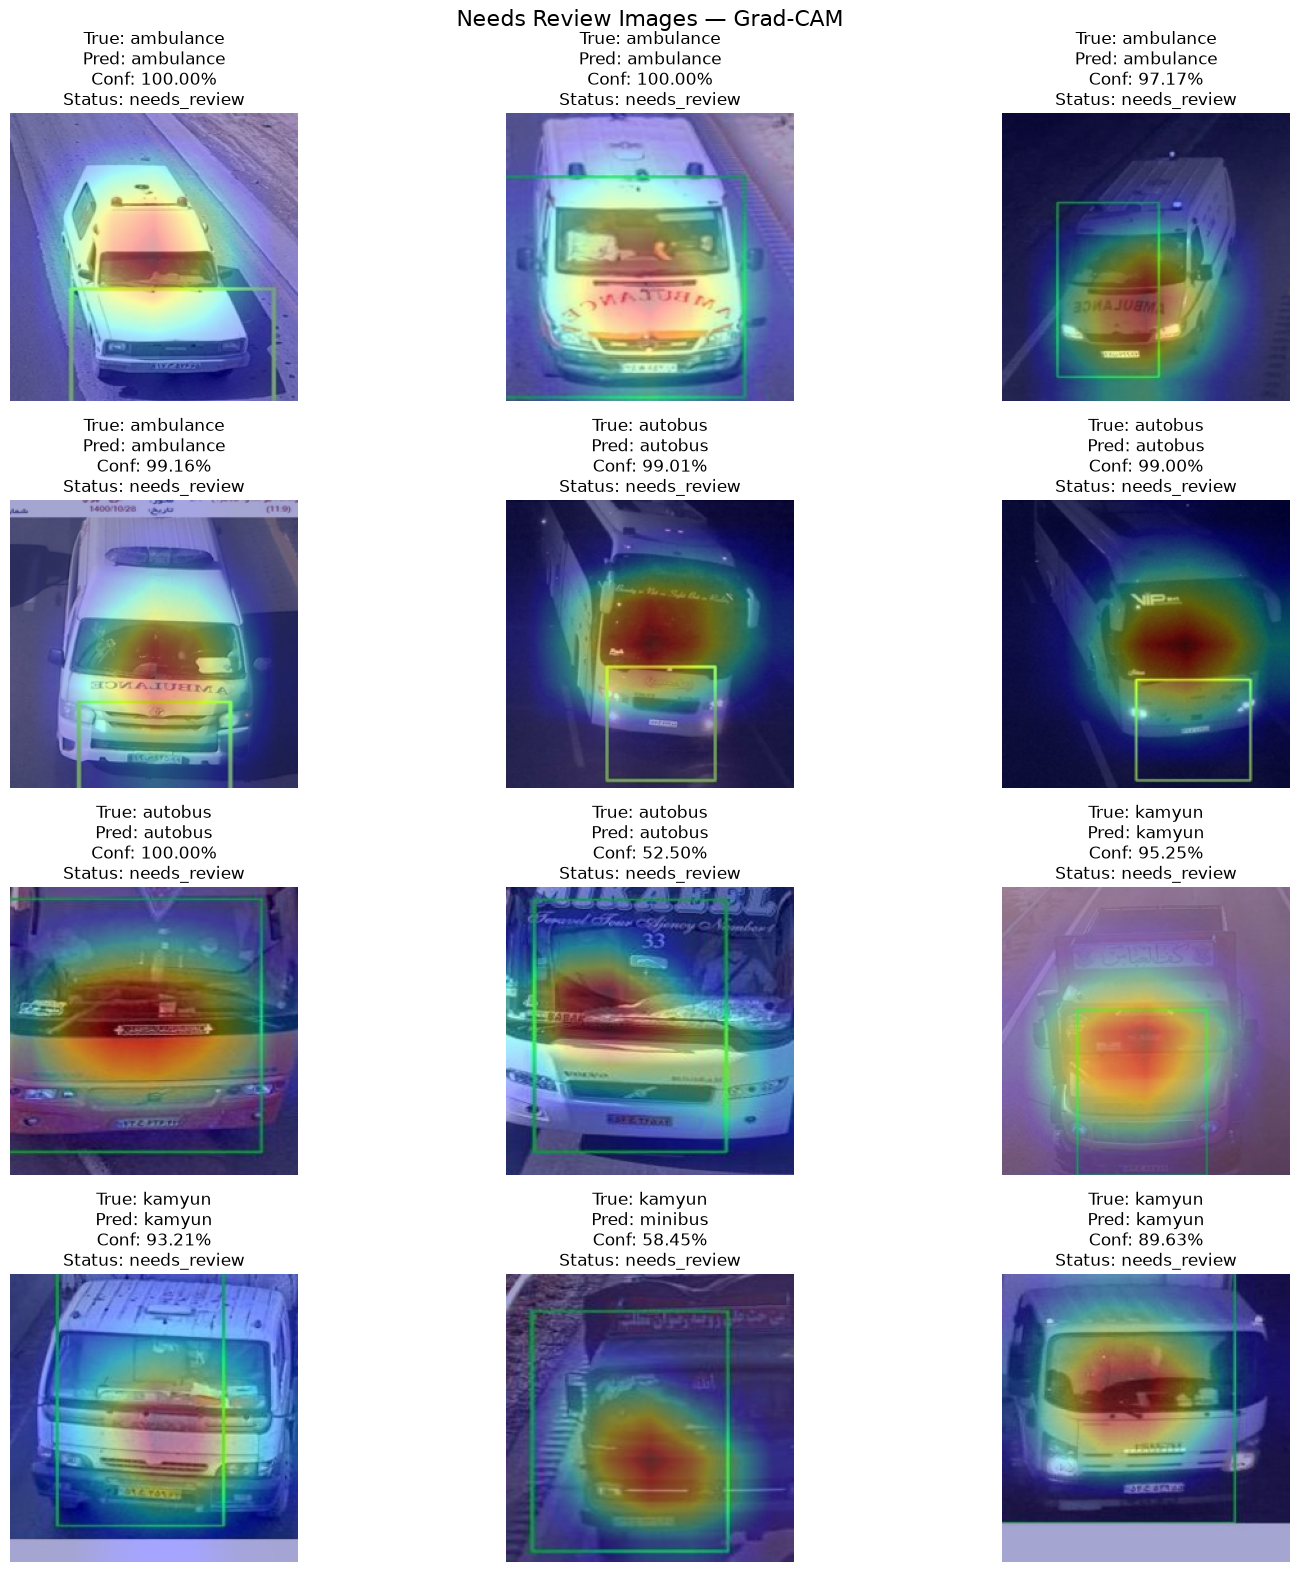

In [29]:
plot_gradcam_dataframe(
    review_results,
    "Needs Review Images — Grad-CAM",
    max_images=12,
    save_dir=GRADCAM_DIR / "needs_review",
    save_all_individual=True,
    save_originals=True,
)


## 17. Neysan Detection Performance

Neysan can be evaluated in two ways:

1. **Explicit Neysan folder inside the selected test dataset** (for example `test1_2/neysan`).
2. **Standalone OOD benchmark** in `dataset/neysan`, which is evaluated separately and does not change the 8-class test mapping.

For `test2`, `test3`, and `test4`, Neysan images may be hidden inside known folders. In that case the notebook reports OOD-suspected images, but exact semantic Neysan detection metrics require an external ground-truth manifest.


In [30]:
# Prefer the selected test dataset's explicit Neysan samples when they exist.
# Otherwise, use the standalone dataset/neysan benchmark so Neysan is still evaluated
# even when it is intentionally kept outside the 8-class test folder.
explicit_nissan_results = results_df[results_df["is_true_nissan"]].copy()

if len(explicit_nissan_results) > 0:
    nissan_results = explicit_nissan_results.copy()
    nissan_source = "selected test dataset"
elif len(standalone_nissan_results) > 0:
    nissan_results = standalone_nissan_results.copy()
    nissan_source = "dataset/neysan (standalone OOD benchmark)"
else:
    nissan_results = pd.DataFrame()
    nissan_source = "none"

print("Neysan evaluation source:", nissan_source)

if len(nissan_results) > 0:
    print("=" * 60)
    print("NEYSAN / NISSAN OOD DETECTION")
    print("=" * 60)

    counts = nissan_results["status"].value_counts()
    for status in ["unknown", "needs_review", "known_failure"]:
        count = counts.get(status, 0)
        rate = (count / len(nissan_results)) * 100
        print(f"{status:15s}: {count:4d} ({rate:.2f}%)")

    detected = nissan_results["status"].isin(["unknown", "needs_review"]).mean()
    print(f"\nTotal Neysan detected by OOD/review: {detected * 100:.2f}%")
else:
    print("No Neysan/Nissan samples were available for evaluation.")

# These subsets are used by the Grad-CAM sections below.
nissan_unknown = nissan_results[nissan_results["status"] == "unknown"].copy()
nissan_review = nissan_results[nissan_results["status"] == "needs_review"].copy()
nissan_missed = nissan_results[nissan_results["status"] == "known_failure"].copy()

# For mixed test2/test3/test4, save all OOD-suspected images even when
# Neysan ground truth is unavailable.
suspected_ood = results_df[results_df["status"].isin(["unknown", "needs_review"])].copy()
suspected_ood.to_csv(CSV_DIR / "ood_suspected_images.csv", index=False)
print(f"Saved OOD-suspected test images: {CSV_DIR / 'ood_suspected_images.csv'}")


Neysan evaluation source: dataset/neysan (standalone OOD benchmark)
NEYSAN / NISSAN OOD DETECTION
unknown        :   15 (2.56%)
needs_review   :  170 (29.01%)
known_failure  :  401 (68.43%)

Total Neysan detected by OOD/review: 31.57%
Saved OOD-suspected test images: d:\AI Bootcamp_M Sharif\traffic_vehicle_project\results\FinalPredict_OOD\csv\ood_suspected_images.csv


## 18. Plot Neysan Images Marked as Unknown

Saved Grad-CAM grid: d:\AI Bootcamp_M Sharif\traffic_vehicle_project\results\FinalPredict_OOD\gradcam\neysan_unknown\true_neysan_detected_as_unknown_grid.png


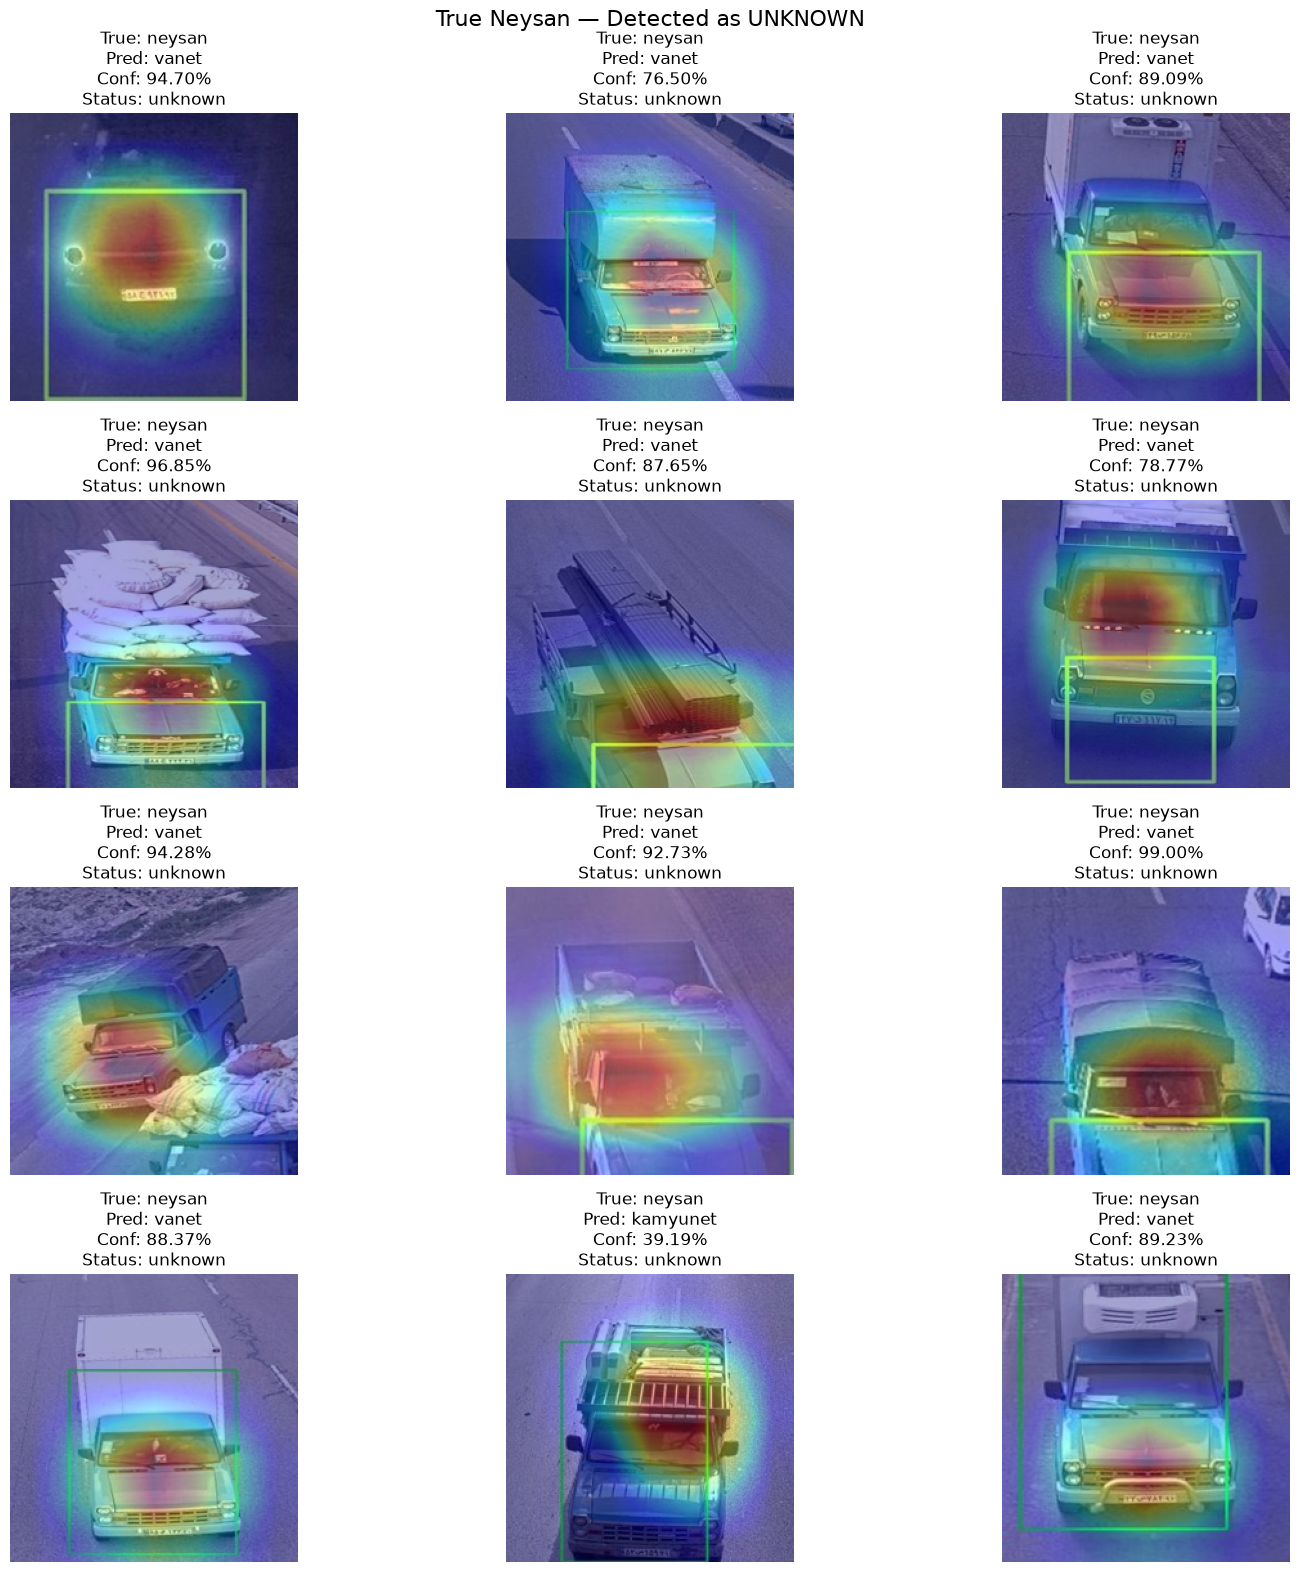

In [31]:
plot_gradcam_dataframe(
    nissan_unknown,
    "True Neysan — Detected as UNKNOWN",
    max_images=12,
    save_dir=GRADCAM_DIR / "neysan_unknown",
    save_all_individual=True,
    save_originals=True,
)


## 19. Plot Neysan Images Marked as Needs Review

Saved Grad-CAM grid: d:\AI Bootcamp_M Sharif\traffic_vehicle_project\results\FinalPredict_OOD\gradcam\neysan_needs_review\true_neysan_detected_as_needs_review_grid.png


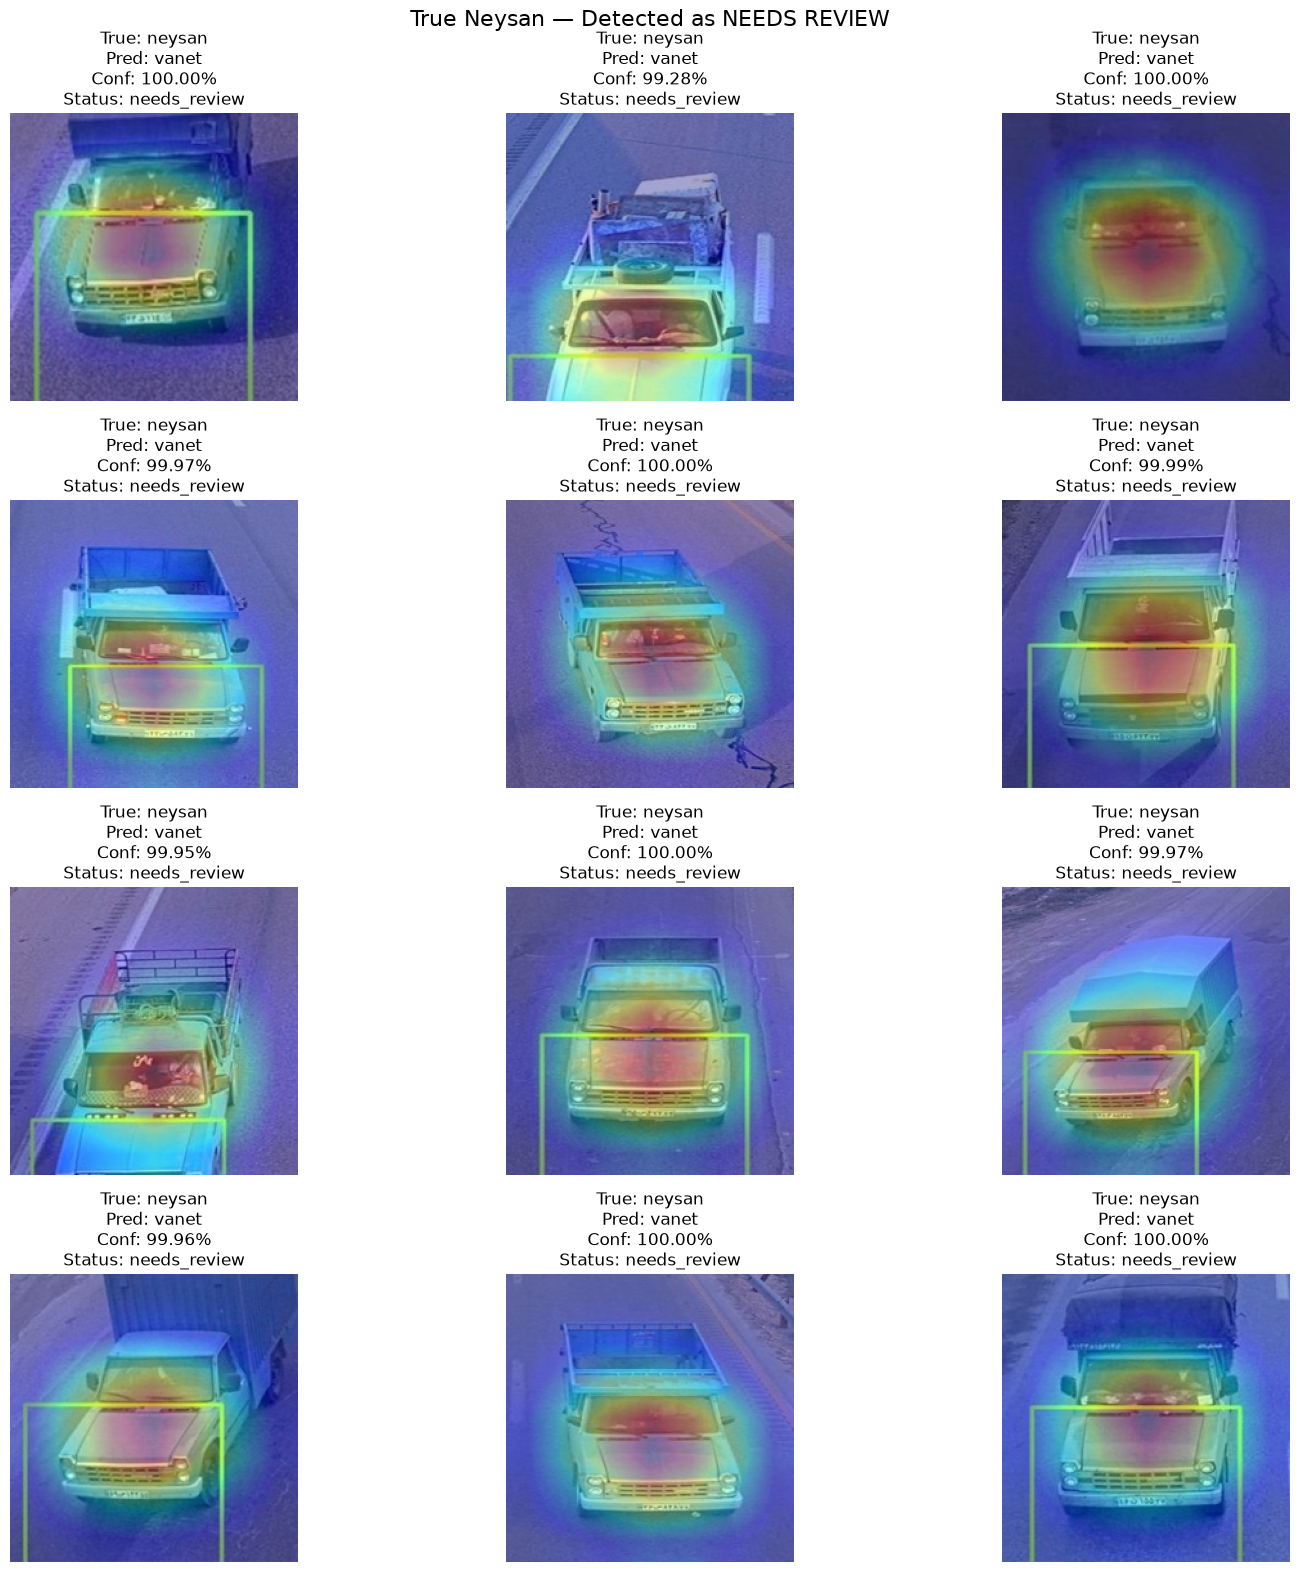

In [32]:
plot_gradcam_dataframe(
    nissan_review,
    "True Neysan — Detected as NEEDS REVIEW",
    max_images=12,
    save_dir=GRADCAM_DIR / "neysan_needs_review",
    save_all_individual=True,
    save_originals=True,
)


## 20. Plot Neysan Images Missed by OOD Detector

This is the most important OOD failure case.

These images are truly `neysan`, but the detector accepted them as known and therefore failed to identify them as OOD.

Saved Grad-CAM grid: d:\AI Bootcamp_M Sharif\traffic_vehicle_project\results\FinalPredict_OOD\gradcam\neysan_missed\true_neysan_ood_missed_known_failure_grid.png


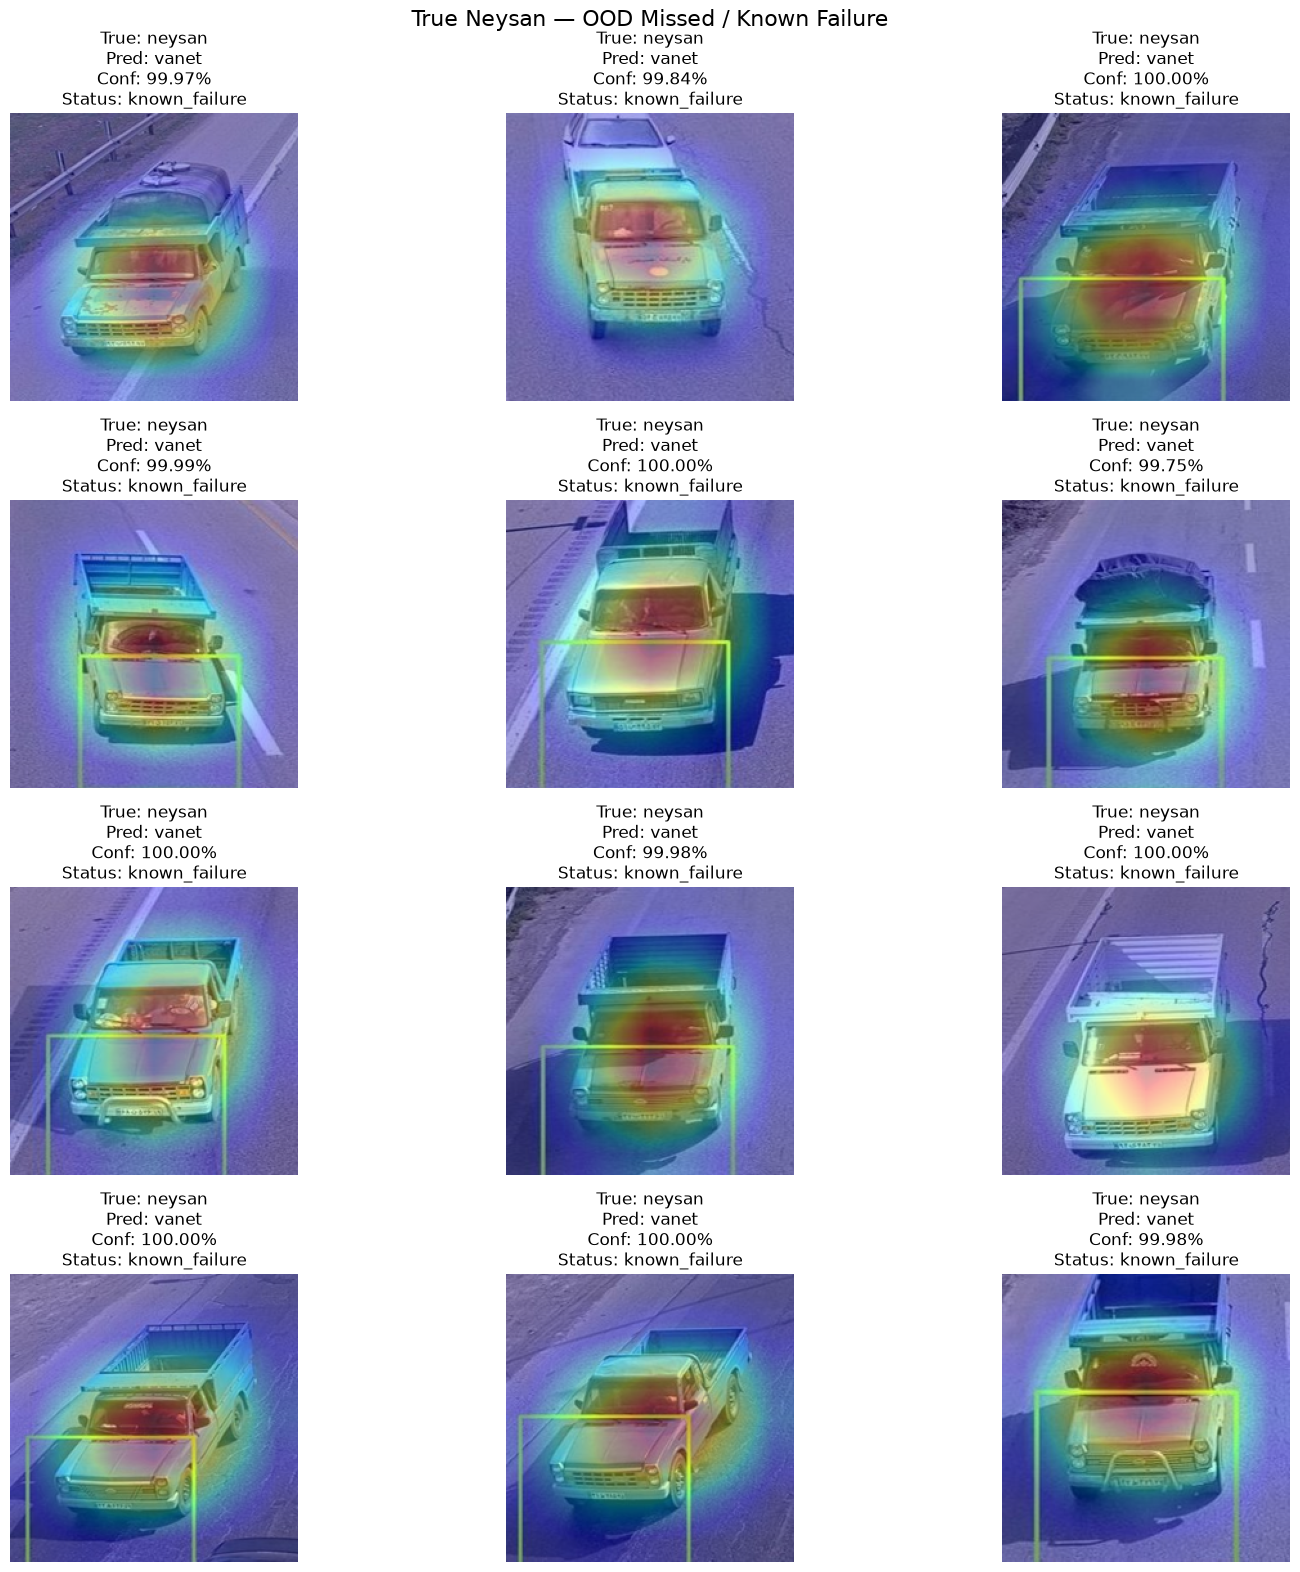

In [33]:
plot_gradcam_dataframe(
    nissan_missed,
    "True Neysan — OOD Missed / Known Failure",
    max_images=12,
    save_dir=GRADCAM_DIR / "neysan_missed",
    save_all_individual=True,
    save_originals=True,
)


## 21. Confusion Matrix — Known Classes

Saved: d:\AI Bootcamp_M Sharif\traffic_vehicle_project\results\FinalPredict_OOD\confusion_matrix_known.png


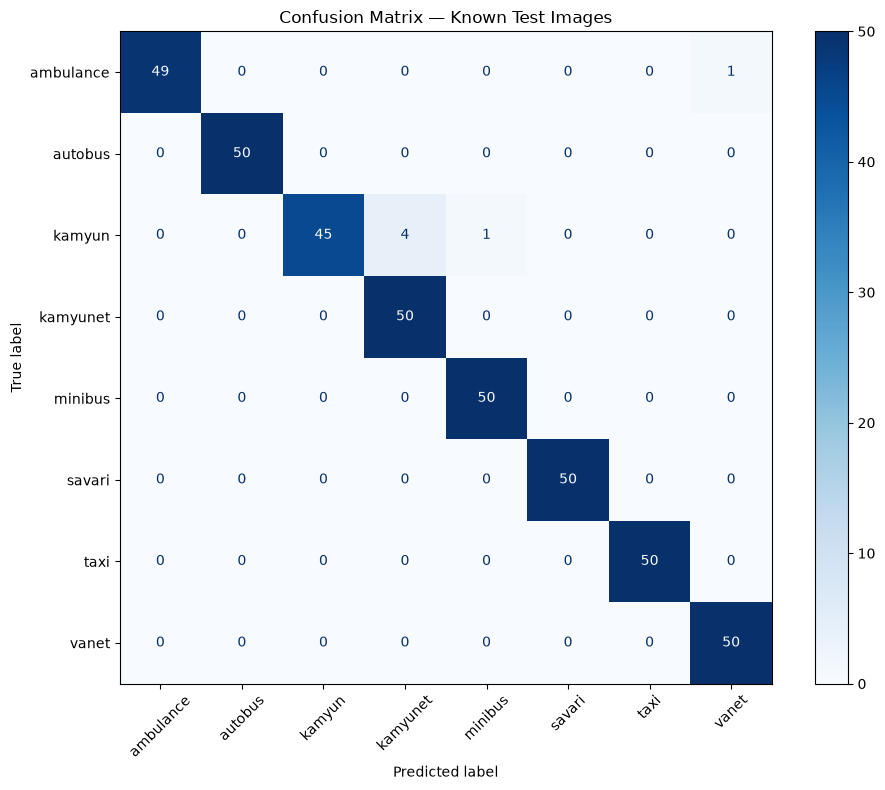

In [34]:
known_true = known_results[
    "true_class"
]

known_pred = known_results[
    "predicted_class"
]

known_class_order = class_names

cm = confusion_matrix(
    known_true,
    known_pred,
    labels=known_class_order
)

fig, ax = plt.subplots(
    figsize=(10, 8)
)

disp = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=known_class_order
)

disp.plot(
    ax=ax,
    xticks_rotation=45,
    cmap="Blues"
)

plt.title(
    "Confusion Matrix — Known Test Images"
)

plt.tight_layout()
fig.savefig(RESULTS_DIR / "confusion_matrix_known.png", dpi=200, bbox_inches="tight")
pd.DataFrame(cm, index=known_class_order, columns=known_class_order).to_csv(CSV_DIR / "confusion_matrix_known.csv")
print(f"Saved: {RESULTS_DIR / 'confusion_matrix_known.png'}")
plt.show()


## 22. Normalized Confusion Matrix

Saved: d:\AI Bootcamp_M Sharif\traffic_vehicle_project\results\FinalPredict_OOD\confusion_matrix_normalized.png


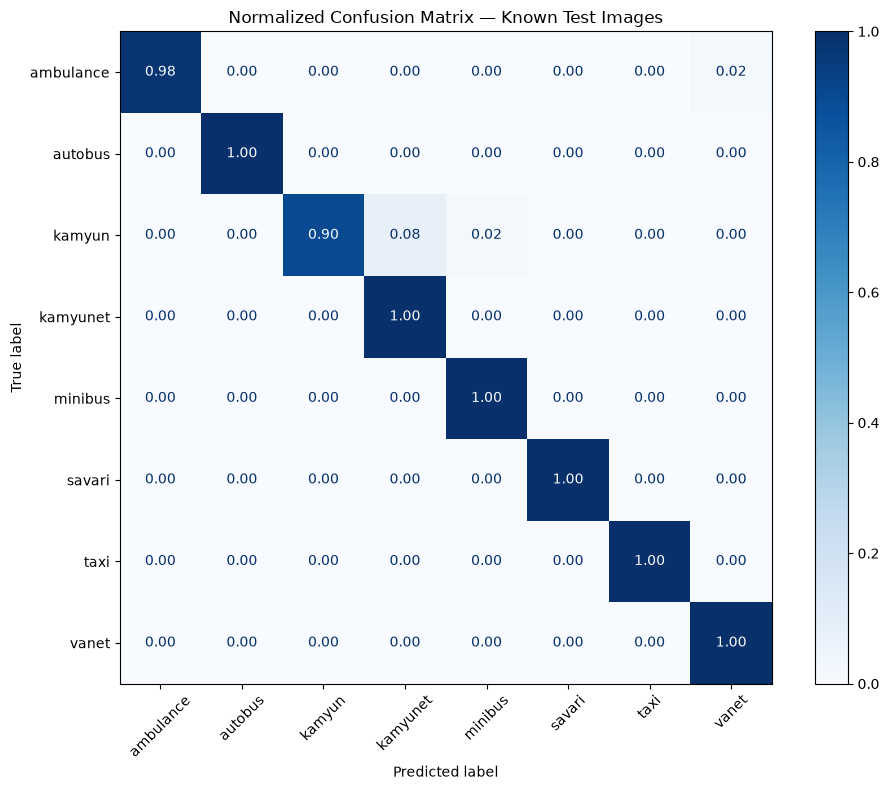

In [35]:
cm_norm = confusion_matrix(
    known_true,
    known_pred,
    labels=known_class_order,
    normalize="true"
)

fig, ax = plt.subplots(
    figsize=(10, 8)
)

disp = ConfusionMatrixDisplay(
    confusion_matrix=cm_norm,
    display_labels=known_class_order
)

disp.plot(
    ax=ax,
    xticks_rotation=45,
    cmap="Blues",
    values_format=".2f"
)

plt.title(
    "Normalized Confusion Matrix — Known Test Images"
)

plt.tight_layout()
fig.savefig(RESULTS_DIR / "confusion_matrix_normalized.png", dpi=200, bbox_inches="tight")
pd.DataFrame(cm_norm, index=known_class_order, columns=known_class_order).to_csv(CSV_DIR / "confusion_matrix_normalized.csv")
print(f"Saved: {RESULTS_DIR / 'confusion_matrix_normalized.png'}")
plt.show()


## 23. Classification Report

In [36]:
report_text = classification_report(
    known_true,
    known_pred,
    labels=known_class_order,
    target_names=known_class_order,
    digits=4,
)
print(report_text)

report_dict = classification_report(
    known_true,
    known_pred,
    labels=known_class_order,
    target_names=known_class_order,
    digits=4,
    output_dict=True,
)
report_df = pd.DataFrame(report_dict).transpose()
report_df.to_csv(CSV_DIR / "classification_report.csv")
with open(RESULTS_DIR / "classification_report.txt", "w", encoding="utf-8") as f:
    f.write(report_text)

print(f"Saved: {CSV_DIR / 'classification_report.csv'}")
print(f"Saved: {RESULTS_DIR / 'classification_report.txt'}")


              precision    recall  f1-score   support

   ambulance     1.0000    0.9800    0.9899        50
     autobus     1.0000    1.0000    1.0000        50
      kamyun     1.0000    0.9000    0.9474        50
    kamyunet     0.9259    1.0000    0.9615        50
     minibus     0.9804    1.0000    0.9901        50
      savari     1.0000    1.0000    1.0000        50
        taxi     1.0000    1.0000    1.0000        50
       vanet     0.9804    1.0000    0.9901        50

    accuracy                         0.9850       400
   macro avg     0.9858    0.9850    0.9849       400
weighted avg     0.9858    0.9850    0.9849       400

Saved: d:\AI Bootcamp_M Sharif\traffic_vehicle_project\results\FinalPredict_OOD\csv\classification_report.csv
Saved: d:\AI Bootcamp_M Sharif\traffic_vehicle_project\results\FinalPredict_OOD\classification_report.txt


## 24. Final Summary Table

In [37]:
summary = {
    "Known Test Loss": known_loss,
    "Known Test Accuracy": known_accuracy,
    "Total Test Images": len(results_df),
    "Wrong Known Predictions": len(wrong_predictions),
    "Unknown": int(
        (results_df["status"] == "unknown").sum()
    ),
    "Needs Review": int(
        (results_df["status"] == "needs_review").sum()
    ),
    "Known": int(
        (results_df["status"] == "known").sum()
    ),
    "Neysan Known Failures": int(
        (results_df["status"] == "known_failure").sum()
    ),
    "Energy Threshold": energy_threshold,
    "Mahalanobis Threshold": maha_threshold,
}

summary_df = pd.DataFrame(
    summary.items(),
    columns=["Metric", "Value"]
)

display(summary_df)

summary_df.to_csv(CSV_DIR / "final_summary.csv", index=False)
print(f"Saved: {CSV_DIR / 'final_summary.csv'}")


,Metric,Value
0,Known Test Loss,0.064108
1,Known Test Accuracy,0.985000
2,Total Test Images,400.000000
3,Wrong Known Predictions,6.000000
4,Unknown,3.000000
5,Needs Review,47.000000
6,Known,350.000000
7,Neysan Known Failures,0.000000
8,Energy Threshold,-5.905742
9,Mahalanobis Threshold,20.151190


Saved: d:\AI Bootcamp_M Sharif\traffic_vehicle_project\results\FinalPredict_OOD\csv\final_summary.csv


# Final Interpretation

This notebook evaluates the 8-class ResNet18 model across the project's test protocols.

### Supported test protocols

- `test0`: standard 8-class evaluation.
- `test1_2`: 9-class test with explicit Neysan support; the ninth class is treated as OOD and does not change the model's 8-class output layer.
- `test2`, `test3`, `test4`: mixed/relabeled datasets. OOD scores and `unknown` / `needs_review` flags are produced, but exact Neysan detection metrics require an external ground-truth manifest when Neysan is hidden inside known folders.

Thresholds are never learned from Neysan. They are computed only from known validation data using `quantile = 0.95` and then fixed for both the selected test dataset and the standalone `dataset/neysan` OOD benchmark.


## 25. Saved Outputs

After running the notebook, reusable outputs are stored under:

```text
results/FinalPredict_OOD/
```

The CSV files contain complete per-image results, wrong predictions, unknown predictions, needs-review predictions, Neysan OOD results when ground truth exists, confusion matrices, classification report, and final summary.

For test2/test3/test4, if `GROUND_TRUTH_CSV` is not provided, the notebook explicitly treats Neysan detection as **OOD suspicion**, not verified ground-truth detection.

The Grad-CAM folders contain individual Grad-CAM overlays and original images for each group. Notebook display remains limited to the first 12 images for readability, while individual files can be saved for all rows.

The standalone Neysan benchmark is saved as `csv/standalone_neysan_results.csv` and its Grad-CAM outputs use the same Neysan-specific folders below `gradcam/`.
